<a class="anchor" id="0"></a>
# **Mubileum Duration Generation with VAE**

<a class="anchor" id="0.1"></a>
# **Table of Contents**

- 1. [Setup](#1)
- 2. [Data Preparation](#2)
<!--     - 2.1 [Data Preparation for LSTM](#2.1) -->
- 3. [EDA](#3)
- 4. [Anomaly Detection](#4)
- 5. [Anomaly Creation](#5)
- 6. [Genetic Algoritm Otimization](#6)


# **1. SetUp** <a class="anchor" id="1"></a>

[Table of Contents](#0.1)

In [1]:
# Data Manipulation and Analysis
import numpy as np
import pandas as pd

#Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Scikit-Learn for Machine Learning
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OrdinalEncoder

# TensorFlow and Keras for Deep Learning
import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, LSTM, Dense, Lambda, RepeatVector
from tensorflow.keras import backend as K

# **2. Data Preparation** <a class="anchor" id="2"></a>

[Table of Contents](#0.1)

In [2]:
# Read a CSV file into a Pandas DataFrame
df = pd.read_csv("/kaggle/input/mobileum/jul_aug_sep_oct_2022_msc_1.csv", sep=";")

# Convert Start Date and Start Hour into a datetime object and set as index
df['TIMESTAMP'] = pd.to_datetime(df['Start Date'] + ' ' + df['Start Hour'].astype(str), format='%d/%m/%Y %H')
df.set_index("TIMESTAMP", inplace=True)

# Clean the #Events column, remove any non-numeric characters, fill NaNs with 0, and convert to integer
df['#Events'] = df['#Events'].str.replace(r'[^\d.-]', '', regex=True)
df['#Events'] = df['#Events'].fillna(0)
df['#Events'] = pd.to_numeric(df['#Events']).astype(int)

# Drop unnecessary columns
# df.drop(columns=['Datasource', 'Start Date', 'Start Hour'], inplace=True) 
df.drop(columns=['Datasource', 'Start Date', 'Start Hour', 'Event Duration'], inplace=True)

# Drop duplicates
df.drop_duplicates(inplace=True)

In [3]:
df.head()

,Call Type,Event Type,Subscriber Type,Traffic Type,Service Type,Partner Description,#Events
TIMESTAMP,,,,,,,
2022-07-18,SMS,ORIGINATED,Postpaid,OFF-NET,NOT-ROAMING,P_0001,105
2022-07-18,VOICE,CALL FORWARD,Application,INT,NOT-ROAMING,P_0001,16
2022-07-18,VOICE,TERMINATED,Roamer In,INT,NOT-ROAMING,P_0002,7
2022-07-18,VOICE,TERMINATED,Roamer In,INT,NOT-ROAMING,P_0003,15
2022-07-18,VOICE,TERMINATED,Roamer In,INT,NOT-ROAMING,P_0004,1


In [4]:
df.describe().round()

,#Events
count,145521.0
mean,15305.0
std,78771.0
min,0.0
25%,118.0
50%,806.0
75%,8676.0
max,3053227.0


# **3. EDA** <a class="anchor" id="3"></a>

[Table of Contents](#0.1)

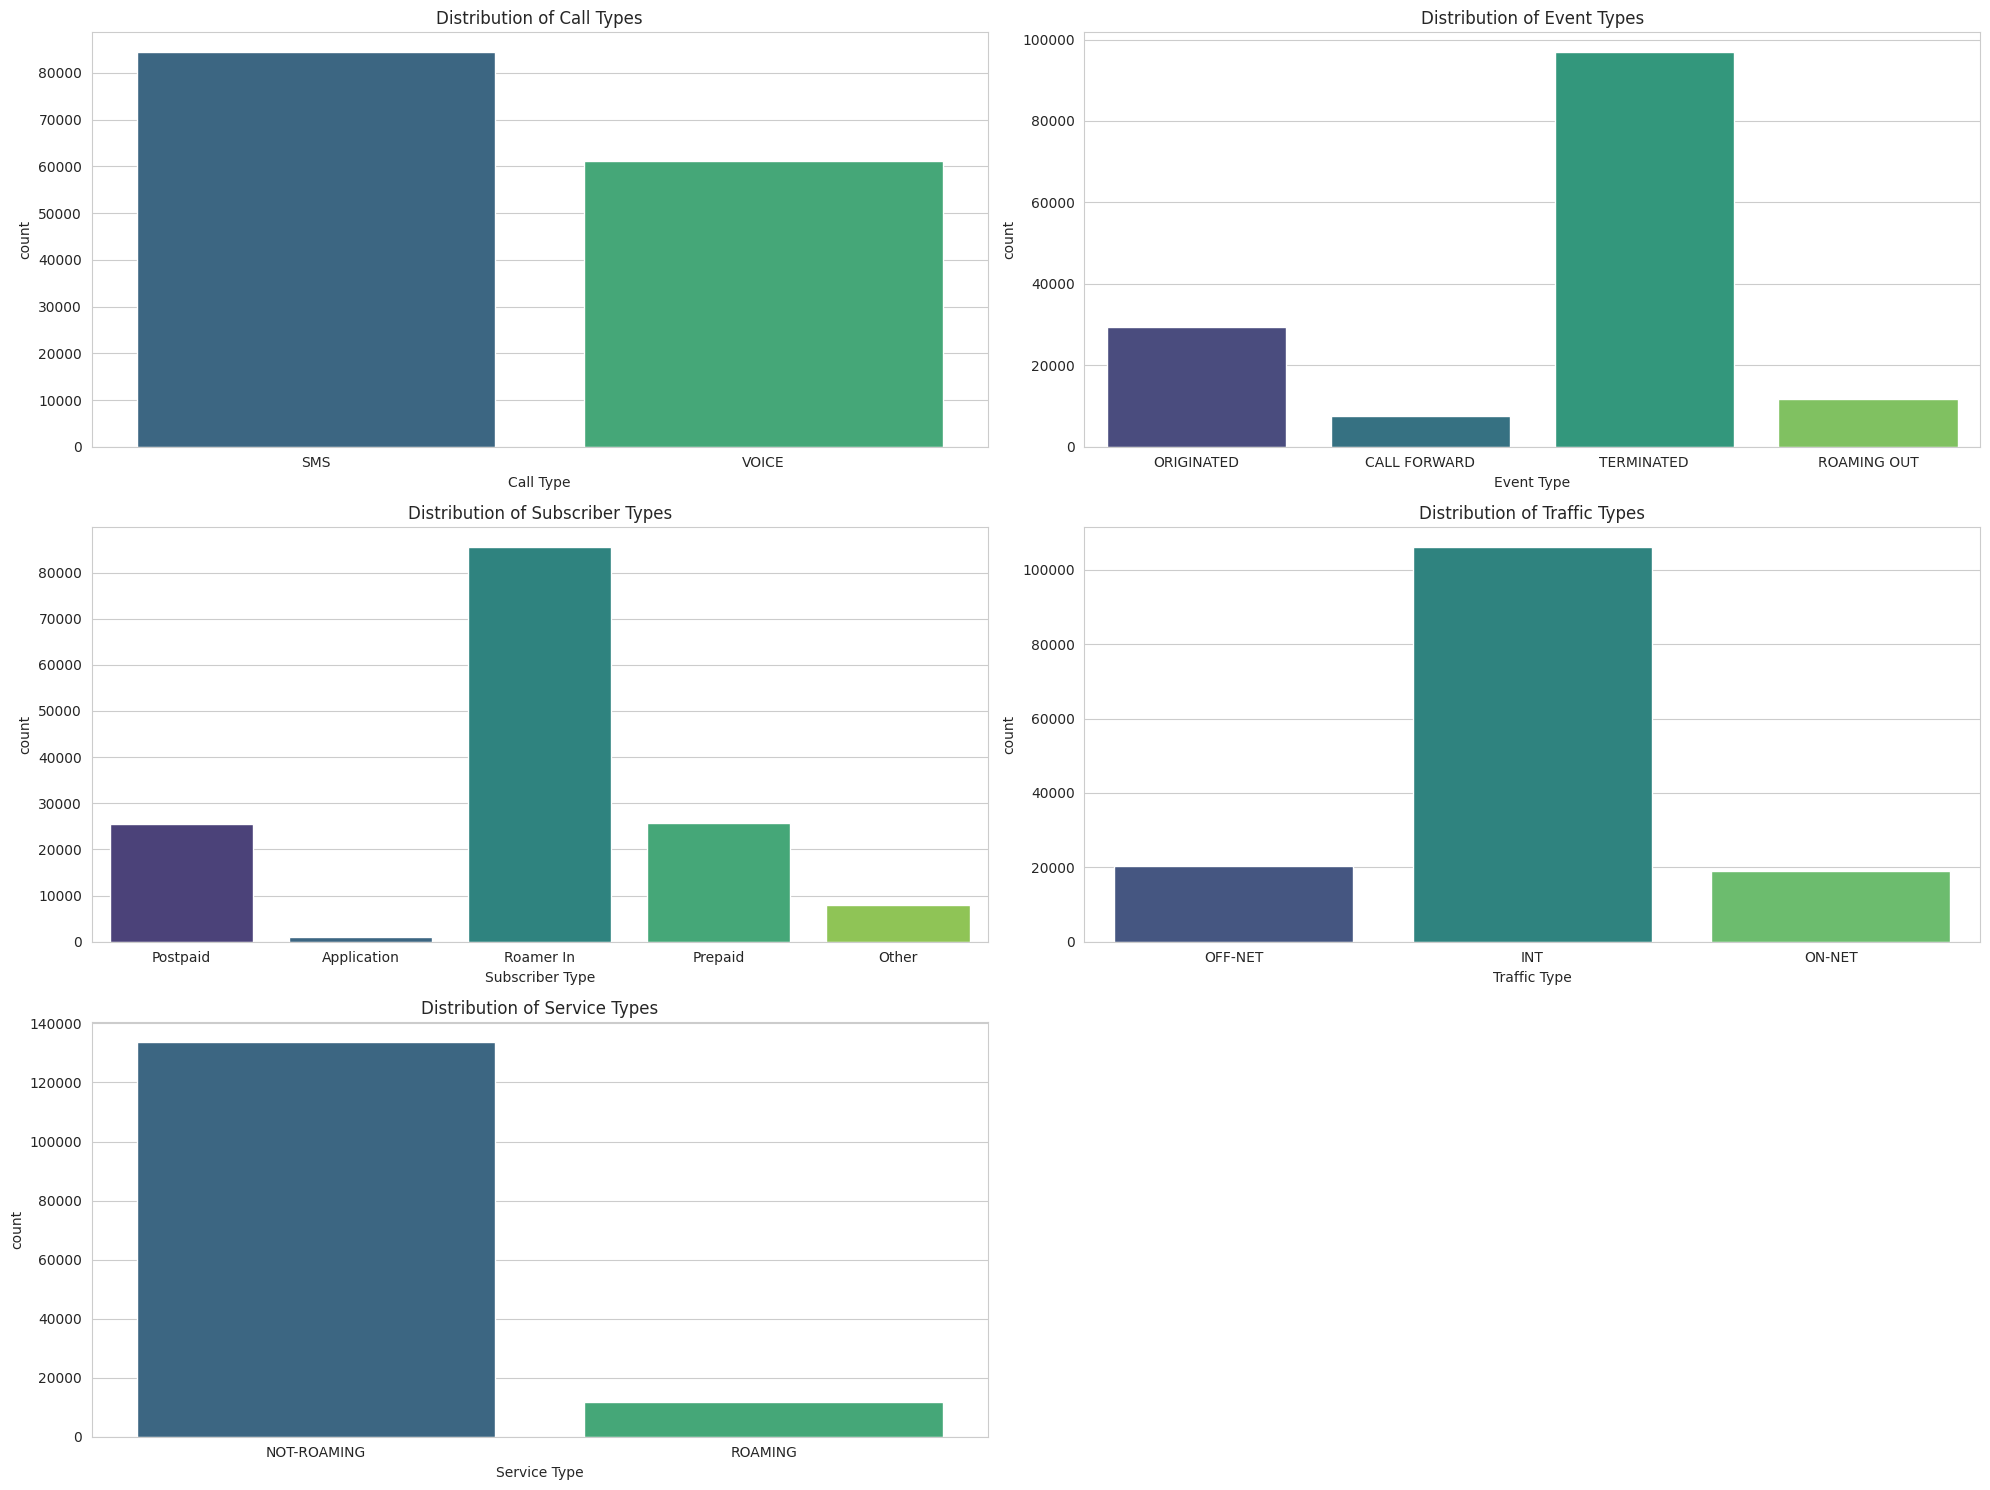

In [5]:
# Set the aesthetic style of the plots
sns.set_style("whitegrid")

# Create a figure to hold the subplots
plt.figure(figsize=(20, 15))

# Distribution of Call Types
plt.subplot(3, 2, 1)
sns.countplot(x='Call Type', data=df, palette='viridis')
plt.title('Distribution of Call Types')

# Distribution of Event Types
plt.subplot(3, 2, 2)
sns.countplot(x='Event Type', data=df, palette='viridis')
plt.title('Distribution of Event Types')

# Distribution of Subscriber Types
plt.subplot(3, 2, 3)
sns.countplot(x='Subscriber Type', data=df, palette='viridis')
plt.title('Distribution of Subscriber Types')

# Distribution of Traffic Types
plt.subplot(3, 2, 4)
sns.countplot(x='Traffic Type', data=df, palette='viridis')
plt.title('Distribution of Traffic Types')

# Distribution of Service Types
plt.subplot(3, 2, 5)
sns.countplot(x='Service Type', data=df, palette='viridis')
plt.title('Distribution of Service Types')

# Adjust layout to make room for the titles and prevent overlap
plt.tight_layout()

plt.show()

In [6]:
from ydata_profiling import ProfileReport

/opt/conda/lib/python3.10/site-packages/numba/core/decorators.py:262: NumbaDeprecationWarning: numba.generated_jit is deprecated. Please see the documentation at: https://numba.readthedocs.io/en/stable/reference/deprecation.html#deprecation-of-generated-jit for more information and advice on a suitable replacement.
  warnings.warn(msg, NumbaDeprecationWarning)
/opt/conda/lib/python3.10/site-packages/visions/backends/shared/nan_handling.py:51: NumbaDeprecationWarning: The 'nopython' keyword argument was not supplied to the 'numba.jit' decorator. The implicit default value for this argument is currently False, but it will be changed to True in Numba 0.59.0. See https://numba.readthedocs.io/en/stable/reference/deprecation.html#deprecation-of-object-mode-fall-back-behaviour-when-using-jit for details.
  def hasna(x: np.ndarray) -> bool:


In [7]:
profile = ProfileReport(df.reset_index(), title='Pandas Profiling Report', explorative=True)

# Save the report to an HTML file
profile.to_file('ydata_profiling_report.html')

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]

Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

Export report to file:   0%|          | 0/1 [00:00<?, ?it/s]

# **4. Anomaly Creation** <a class="anchor" id="4"></a>

[Table of Contents](#0.1)

In [8]:
def filter_and_aggregate(df, filter_conditions):
    """
    Filters the DataFrame based on given conditions and aggregates by summing up a specified column.
    
    Args:
    - df: The original DataFrame.
    - filter_conditions: A dictionary where keys are column names and values are the values to filter on.
    
    Returns:
    - A new DataFrame with the filtered and aggregated data.
    """
    # Apply the filter conditions
    df_fil = df.copy()
    for col, val in filter_conditions.items():
        df_fil = df_fil[df_fil[col] == val]
    
    # Drop the columns used for filtering
    df_fil.drop(columns=list(filter_conditions.keys()), inplace=True)
    
    # Group by 'TIMESTAMP' and sum up the '#Events' column
    df_agg = df_fil.groupby('TIMESTAMP')['#Events'].sum().reset_index()
    
    return df_agg


In [9]:
# Define your filter conditions here
filter_conditions = {
    'Call Type': 'SMS',
    'Event Type': 'ORIGINATED'
}

# Now use the function with the DataFrame `df` and the filter conditions.
df_fil = filter_and_aggregate(df, filter_conditions)

# Check the first few rows of the resulting DataFrame
print(df_fil.head())

            TIMESTAMP  #Events
0 2022-07-18 00:00:00     1381
1 2022-07-18 01:00:00      929
2 2022-07-18 02:00:00      705
3 2022-07-18 03:00:00      584
4 2022-07-18 04:00:00      691


<Axes: xlabel='TIMESTAMP'>

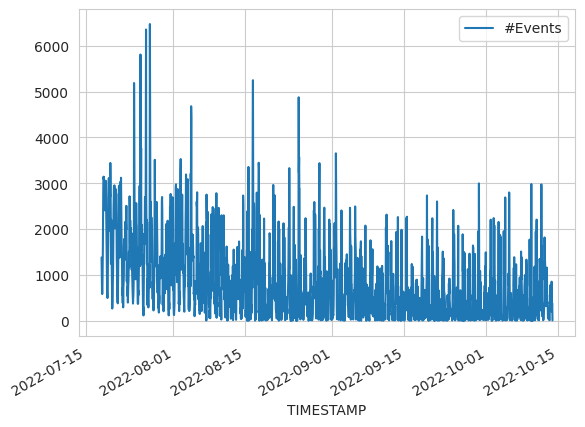

In [10]:
df_fil.plot(x="TIMESTAMP", y="#Events")

<Axes: xlabel='TIMESTAMP'>

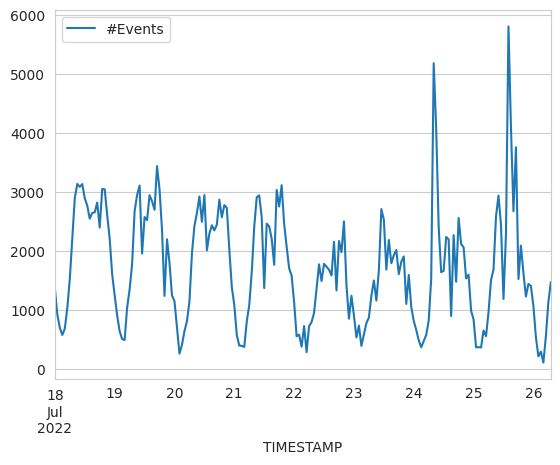

In [11]:
df_fil[:200].plot(x="TIMESTAMP", y="#Events")

In [12]:
def generate_anomaly(mean, std, lower_bound=0):
    """
    Generate a random anomaly value.
    
    Parameters:
    mean (float): The mean value of the normal data.
    std (float): The standard deviation of the normal data.
    lower_bound (int): The minimum value an anomaly can take, inclusive. Default is 0.
    
    Returns:
    int: An anomalous data point.
    """
    upper_normal = mean + 3 * std
    lower_normal = max(mean - 3 * std, lower_bound)
    
    
    # Choose between an anomaly below or above the normal range.
    anomaly_value = np.random.choice([upper_normal, lower_normal])
    return anomaly_value


In [13]:
def insert_anomaly(df_anomaly, index):
    
    start = max(index - 84, 0)
    end = min(index + 83, len(df) - 1)

    std = df_anomaly[start:end]["#Events"].std()
    mean = df_anomaly[start:end]["#Events"].mean()

    anomaly_value = generate_anomaly(mean, std)


    actual_value = df_anomaly.iloc[index]["#Events"]
    df_anomaly.at[df_anomaly.index[index], '#Events'] = anomaly_value
    

#     print(f"Anomaly value: {anomaly_value}")
#     plt.figure(figsize=(10, 6))
#     plt.plot(df.index, df["#Events"], label="Events", marker='o', linestyle='-', markersize=4)
#     plt.scatter(df.index[index], anomaly_value, color='red', s=100, label='Anomaly', zorder=5)
#     plt.xlabel('TIMESTAMP')
#     plt.ylabel('#Events')
#     plt.title('Visualization of #Events with Anomaly Inserted')
#     plt.legend()
#     plt.grid(True)
#     plt.show()
    print( "actual_value: " ,actual_value, "Anomaly_value: ", df_anomaly.iloc[index]["#Events"], "Mean: " , mean, "Std: " , std)
    return mean, std, anomaly_value, actual_value



In [14]:
def insert_nanomaly(df, n_anomalies):
    df_anomaly = df.copy()
    df_anomaly['Anomaly'] = False
    indexes = np.random.choice(range(0, len(df_anomaly)-1), size=n_anomalies, replace=False)
    
    
    for i in indexes:
        insert_anomaly(df_anomaly, i)
    
    df_anomaly["Anomaly"].values[indexes] = True
    
    plt.figure(figsize=(10, 6))
    
    plt.plot(df_anomaly["TIMESTAMP"], df_anomaly["#Events"], label="Events", marker='o', linestyle='-', markersize=4)
    
    plt.scatter(df_anomaly.iloc[indexes]["TIMESTAMP"], df_anomaly["#Events"][indexes], color='red', s=100, label='Anomaly', zorder=5)
    
    plt.xlabel('TIMESTAMP')
    plt.ylabel('#Events')
    plt.title('Visualization of #Events with Anomaly Inserted')
    plt.legend()
    plt.grid(True)
    plt.show()
    
    return df_anomaly

actual_value:  335 Anomaly_value:  2737.6705640321475 Mean:  788.8922155688623 Std:  649.592782821095
actual_value:  20.0 Anomaly_value:  0.0 Mean:  757.1497005988024 Std:  759.5365631144699
actual_value:  145.0 Anomaly_value:  0.0 Mean:  611.2155688622754 Std:  574.9647880235743
actual_value:  2652.0 Anomaly_value:  0.0 Mean:  1969.0408163265306 Std:  897.6917699192581
actual_value:  287.0 Anomaly_value:  2524.4883716529157 Mean:  549.6586826347306 Std:  658.2765630060617
actual_value:  536.0 Anomaly_value:  0.0 Mean:  571.2155688622754 Std:  654.4357646993295
actual_value:  345.0 Anomaly_value:  0.0 Mean:  483.62874251497004 Std:  573.1817400447246
actual_value:  136.0 Anomaly_value:  0.0 Mean:  863.0718562874251 Std:  895.3010435942713
actual_value:  530.0 Anomaly_value:  0.0 Mean:  879.0818596648633 Std:  685.8319903263558
actual_value:  126.0 Anomaly_value:  2592.944197639559 Mean:  569.2663974350473 Std:  674.5592667348374
actual_value:  1592.0 Anomaly_value:  0.0 Mean:  718.2634

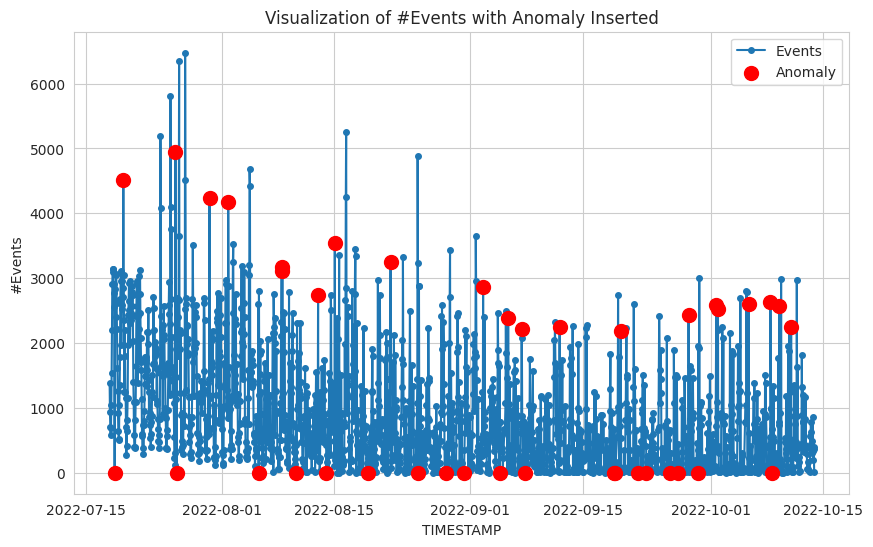

In [15]:
df_anomaly = insert_nanomaly(df_fil, 40)


In [16]:
df_anomaly

,TIMESTAMP,#Events,Anomaly
0,2022-07-18 00:00:00,1381.0,False
1,2022-07-18 01:00:00,929.0,False
2,2022-07-18 02:00:00,705.0,False
3,2022-07-18 03:00:00,584.0,False
4,2022-07-18 04:00:00,691.0,False
...,...,...,...
1905,2022-10-13 17:00:00,854.0,False
1906,2022-10-13 18:00:00,191.0,False
1907,2022-10-13 19:00:00,392.0,False
1908,2022-10-13 20:00:00,370.0,False


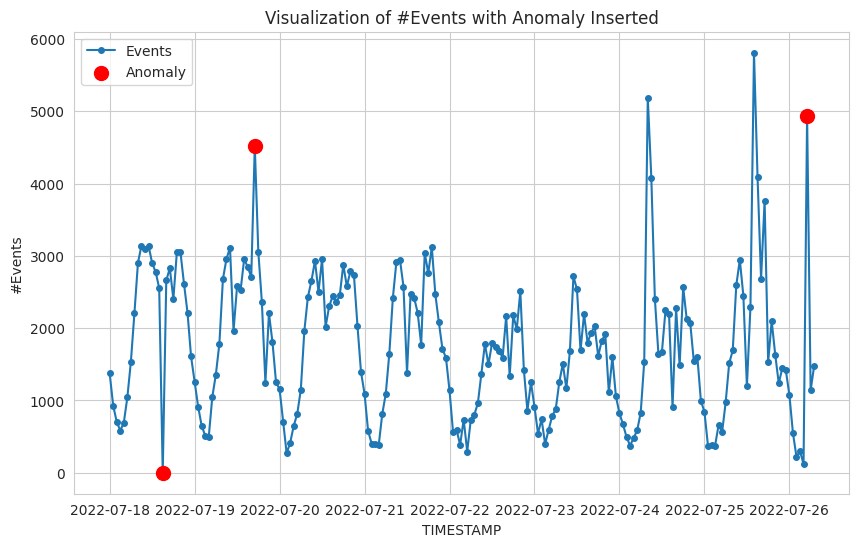

In [17]:
start=0
end=200

aux = df_anomaly[start:end]

indexes = aux[aux["Anomaly"]==True].index
plt.figure(figsize=(10, 6))

plt.plot(aux["TIMESTAMP"], aux["#Events"], label="Events", marker='o', linestyle='-', markersize=4)

# Destacando o valor anômalo
plt.scatter(aux.iloc[(indexes-start).values]["TIMESTAMP"], aux["#Events"][indexes], color='red', s=100, label='Anomaly', zorder=5)

plt.xlabel('TIMESTAMP')
plt.ylabel('#Events')
plt.title('Visualization of #Events with Anomaly Inserted')
plt.legend()
plt.grid(True)
plt.show()

In [18]:
df_anomaly.to_csv("file")

In [19]:
df_anomaly[df_anomaly["Anomaly"].values==True]

,TIMESTAMP,#Events,Anomaly
15,2022-07-18 15:00:00,0.000000,True
41,2022-07-19 17:00:00,4517.948917,True
197,2022-07-26 05:00:00,4937.575944,True
201,2022-07-26 09:00:00,0.000000,True
299,2022-07-30 11:00:00,4234.002931,True
355,2022-08-01 19:00:00,4171.349765,True
446,2022-08-05 14:00:00,0.000000,True
515,2022-08-08 11:00:00,3179.212929,True
517,2022-08-08 13:00:00,3114.470763,True
559,2022-08-10 07:00:00,0.000000,True


Choice one to be the target the anomaly for desaggregated df

## 4.1 Insert the anomaly into desaggregated df

In [20]:
anomaly_choiced = df_anomaly[df_anomaly["Anomaly"].values==True].iloc[0]

In [21]:
anomaly_choiced["TIMESTAMP"]

Timestamp('2022-07-18 15:00:00')

In [22]:
df_modified = df.copy()
# Sexta feira as 16h
df_modified.loc['2022-07-22 16:00:00', '#Events']= round(df_modified.loc['2022-07-22 16:00:00', '#Events'] * 30 / 70)

In [23]:
print("(modified, original)")
(df_modified.loc['2022-07-22 16:00:00', '#Events'].sum(), df.loc['2022-07-22 16:00:00', '#Events'].sum())

(modified, original)


(490591, 1144723)

In [24]:
# Define your filter conditions here
filter_conditions1 = {
    'Call Type': 'SMS'
}

filter_conditions2 = {
    'Call Type': 'SMS',
    'Service Type': 'ROAMING',
    'Event Type': 'TERMINATED',
}


filter_conditions3 = {
    'Call Type': 'VOICE',
    'Service Type': 'ROAMING',
}

In [25]:
original_agg1 = filter_and_aggregate(df, filter_conditions1)
modified_agg1 = filter_and_aggregate(df_modified, filter_conditions1)
original_agg2 = filter_and_aggregate(df, filter_conditions2)
modified_agg2 = filter_and_aggregate(df_modified, filter_conditions2)
original_agg3 = filter_and_aggregate(df, filter_conditions3)
modified_agg3 = filter_and_aggregate(df_modified, filter_conditions3)

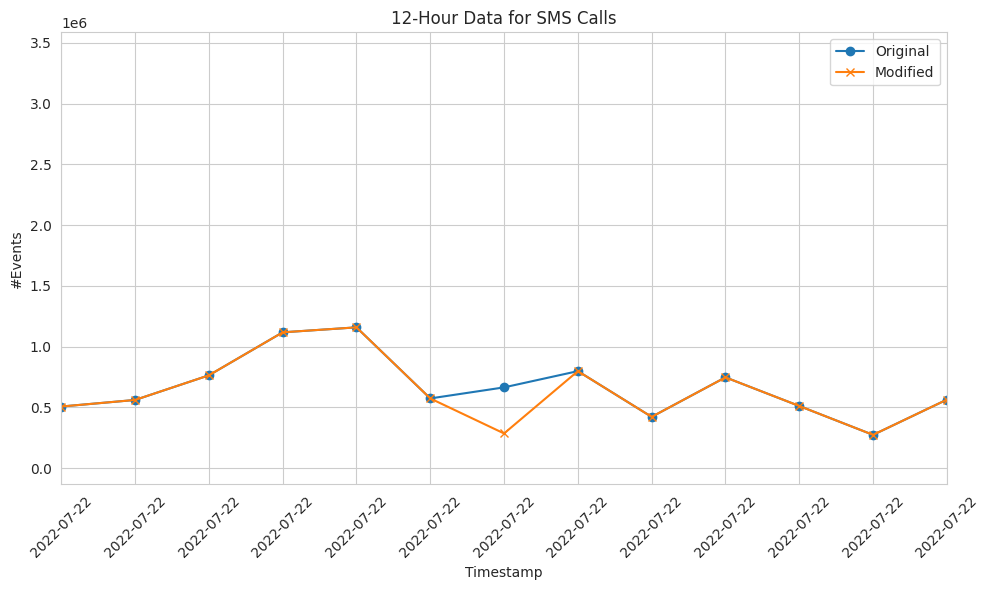

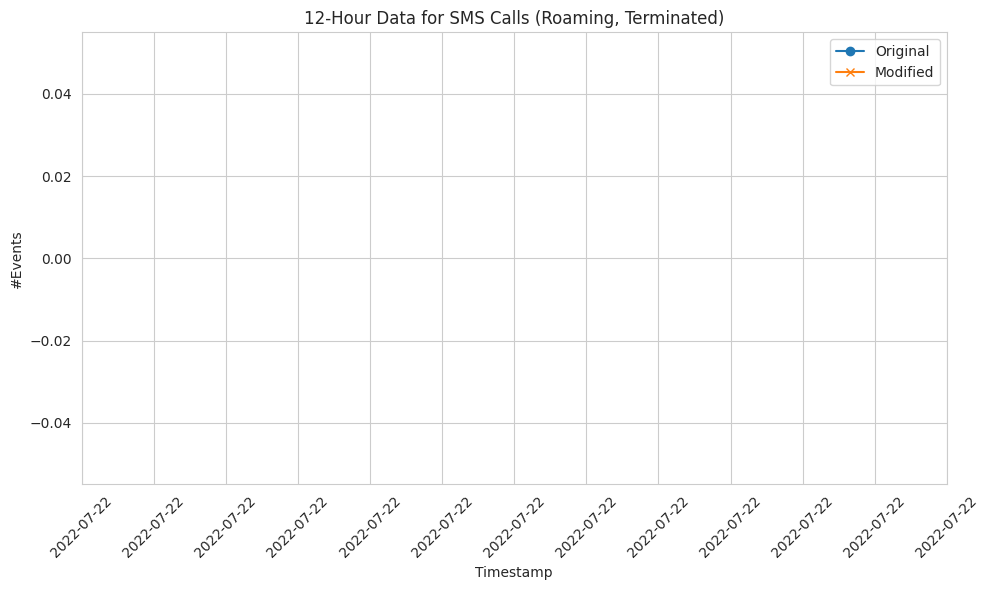

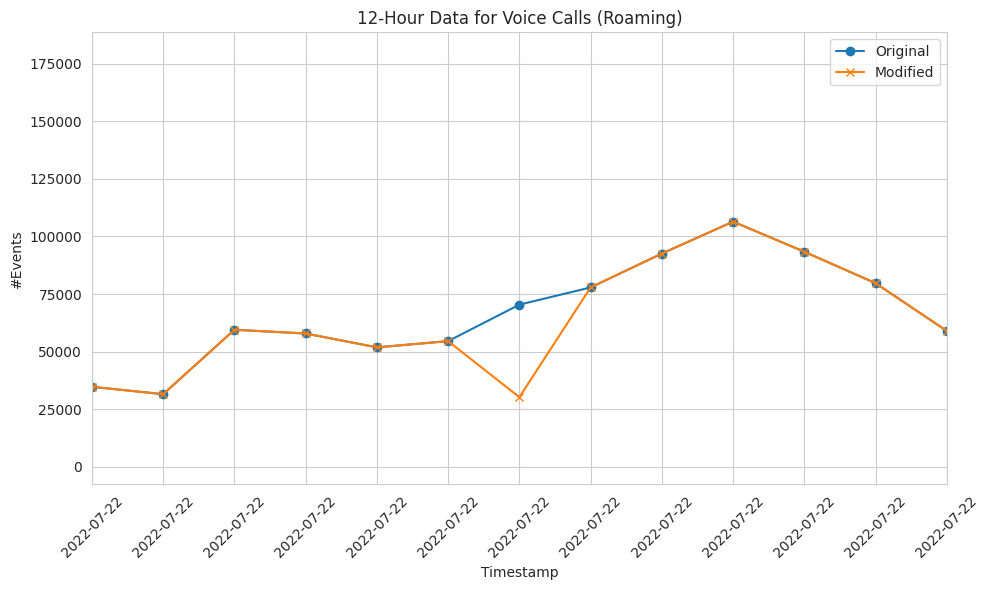

In [26]:
center_timestamp = pd.Timestamp('2022-07-22 16:00:00')
half_day = pd.Timedelta(hours=12)
start_time_half_day = center_timestamp - half_day / 2
end_time_half_day = center_timestamp + half_day / 2

# Function to plot the data with exact axis limits for 12-hour range
def plot_data_exact_12h(df_original, df_modified, title):
    fig, ax = plt.subplots(figsize=(10, 6))
    ax.plot(df_original['TIMESTAMP'], df_original['#Events'], label='Original', marker='o')
    ax.plot(df_modified['TIMESTAMP'], df_modified['#Events'], label='Modified', marker='x')
    ax.set_title(title)
    ax.set_xlabel('Timestamp')
    ax.set_ylabel('#Events')
    ax.legend()
    ax.set_xlim(start_time_half_day, end_time_half_day)  # Set exact 12-hour range
    plt.xticks(pd.date_range(start=start_time_half_day, end=end_time_half_day, freq='H'), rotation=45)
    plt.grid(True)
    plt.tight_layout()

# Replotting the data for exact 12-hour window
plot_data_exact_12h(original_agg1, modified_agg1, '12-Hour Data for SMS Calls')
plot_data_exact_12h(original_agg2, modified_agg2, '12-Hour Data for SMS Calls (Roaming, Terminated)')
plot_data_exact_12h(original_agg3, modified_agg3, '12-Hour Data for Voice Calls (Roaming)')


1. Definir o nivel de agregacao
    Escolher uma categoria
    Escolher um ponto aleatorio
    tirar a media /std da vizinhanca w=168 
    rescrever o valor original +- 3 std max(0, -x)
    

Injetar anomalias de forma global/local
nova coluna / hora
nivel mais fino
desvio padrao de vizinhaca antes e depois 


Anomalias pontuais usando a estatistica de vizinhanca ()
Distribuicao gaussiana

Global/localizada - dataset sintetico
Gramatical evolution
python

VAE (Tensorflow) Ex: Desvio padrão modulo de 3

# **5. Anomaly Detetion** <a class="anchor" id="5"></a>

[Table of Contents](#0.1)

1. label das anomalias
2. hierarquia fixa, calcular Matrix P
3. Optimizacao S

Como a Criacao de janelas series temporais relaciona-se com o seguintes:
Hierarquias
Detecao de anomalias
agoritmos genericos

Matrix Profile
Mais tarde: Pyod (outlier detection)

Distancia minima
AUC (‘threshold’)

## Ao aumentar o quartile a anomalia restringe aos valores dos eventos com duracao excessiva, apesar da duranca aumentar com o tempo seguindo uma periodicidade semanal

verificar as anomalias serem iguais entre os dois colunas ja que tem o mesmo numero de anomalias do Event Duration and #Events

## 5.1 Statistical Thresholding

In [27]:
# Calculate mean and standard deviation of the "#Events" column
mean_events = df_anomaly['#Events'].mean()
std_events = df_anomaly['#Events'].std()

# Define thresholds for anomalies
upper_threshold = mean_events + 3 * std_events
lower_threshold = mean_events - 3 * std_events

# Identify anomalies
df_anomaly['Detected_Anomaly'] = (df_anomaly['#Events'] > upper_threshold) | (df_anomaly['#Events'] < lower_threshold)

# Count the detected anomalies and display the rows with anomalies
anomaly_count = df_anomaly['Detected_Anomaly'].sum()
anomaly_data = df_anomaly[df_anomaly['Detected_Anomaly']]

anomaly_count, anomaly_data.head()


(19,
               TIMESTAMP      #Events  Anomaly  Detected_Anomaly
 41  2022-07-19 17:00:00  4517.948917     True              True
 152 2022-07-24 08:00:00  5188.000000    False              True
 153 2022-07-24 09:00:00  4083.000000    False              True
 182 2022-07-25 14:00:00  5810.000000    False              True
 183 2022-07-25 15:00:00  4095.000000    False              True)

In [28]:
from sklearn.metrics import confusion_matrix

# Labels are the 'Anomaly' column from the dataset
y = df_anomaly['Anomaly']

# Predictions from statistical thresholding
y_pred = df_anomaly['Detected_Anomaly']

cm = confusion_matrix(y, y_pred)
cm

array([[1855,   15],
       [  36,    4]])

In [29]:
from sklearn.metrics import f1_score

f1_score(y, y_pred)

0.13559322033898305

In [30]:
# from sklearn.metrics import roc_curve

# fpr, tpr, thresholds = roc_curve(true_labels, y_scores)

# idx_for_threshold_at_90 = (thresholds <= threshold_for_90_precision).argmax()
# tpr_90, fpr_90 = tpr[idx_for_threshold_at_90], fpr[idx_for_threshold_at_90]

# plt.figure(figsize=(6, 5))  # extra code – not needed, just formatting
# plt.plot(fpr, tpr, linewidth=2, label="ROC curve")
# plt.plot([0, 1], [0, 1], 'k:', label="Random classifier's ROC curve")
# plt.plot([fpr_90], [tpr_90], "ko", label="Threshold for 90% precision")

# # extra code – just beautifies and saves Figure 3–7
# plt.gca().add_patch(patches.FancyArrowPatch(
#     (0.20, 0.89), (0.07, 0.70),
#     connectionstyle="arc3,rad=.4",
#     arrowstyle="Simple, tail_width=1.5, head_width=8, head_length=10",
#     color="#444444"))
# plt.text(0.12, 0.71, "Higher\nthreshold", color="#333333")
# plt.xlabel('False Positive Rate (Fall-Out)')
# plt.ylabel('True Positive Rate (Recall)')
# plt.grid()
# plt.axis([0, 1, 0, 1])
# plt.legend(loc="lower right", fontsize=13)
# save_fig("roc_curve_plot")


# **6. Genetic Algoritm Optimization** <a class="anchor" id="6"></a>

[Table of Contents](#0.1)

As hierarquias so entram aqui nesta fase?
as anomalias agregam, so basta ter um dos valores da juncao positiva para ser anomalia

Amostragem aleatória das hierarquias
Definir população inicial
Como fazer as mutações

Genetic Programing

Ex: 
 > Comocar com 100 aleatorias e avaliamos o fitness (F1 score)
 > > 100 hieraquias aleatorias
 > Escolher as 20 melhores e fazer multacoes ate termos uma nova populacao de 100 
 > Paragem:
 > > O melhor F1 score da populacao nao aumenta mais que 1%
 > >


In [31]:
df

,Call Type,Event Type,Subscriber Type,Traffic Type,Service Type,Partner Description,#Events
TIMESTAMP,,,,,,,
2022-07-18 00:00:00,SMS,ORIGINATED,Postpaid,OFF-NET,NOT-ROAMING,P_0001,105
2022-07-18 00:00:00,VOICE,CALL FORWARD,Application,INT,NOT-ROAMING,P_0001,16
2022-07-18 00:00:00,VOICE,TERMINATED,Roamer In,INT,NOT-ROAMING,P_0002,7
2022-07-18 00:00:00,VOICE,TERMINATED,Roamer In,INT,NOT-ROAMING,P_0003,15
2022-07-18 00:00:00,VOICE,TERMINATED,Roamer In,INT,NOT-ROAMING,P_0004,1
...,...,...,...,...,...,...,...
2022-10-13 21:00:00,SMS,TERMINATED,Roamer In,INT,NOT-ROAMING,P_0042,209
2022-10-13 21:00:00,SMS,TERMINATED,Postpaid,OFF-NET,NOT-ROAMING,P_0001,3748
2022-10-13 21:00:00,SMS,TERMINATED,Prepaid,INT,NOT-ROAMING,P_0001,11801
